# 🌍 World Happiness Report — Exploratory Data Analysis (EDA)
**Pluto Academy AI & Machine Learning Internship — Project 01**

- **Author:** Shivshankar Dhareppa Mali
- **Candidate Ref:** `PA-OL-AIML-2026-0934`
- **Dataset:** [World Happiness Report (Kaggle / UNSDSN)](https://www.kaggle.com/datasets/unsdsn/world-happiness)
- **Goal:** Comprehensive EDA answering 5 core questions, 6+ publication visualizations, and 5 data-backed insights.


### 📦 1. Import Core Libraries

In [1]:
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')


### 🎨 2. Set Visualization Styling

In [2]:
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.autolayout': True,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'legend.frameon': True
})


### 📂 3. Locate Dataset Directory

In [3]:
# Compatible with Google Colab or local repo
data_dir = Path("data") if Path("data").exists() else Path("project-01-world-happiness-eda/data")
print("Data directory:", data_dir.resolve())


Data directory: D:\Internships\AI & ML Internship\project-01-world-happiness-eda\data


### 🔎 4. Inspect Available CSV Datasets

In [4]:
csv_files = sorted(list(data_dir.glob("*.csv")))
for f in csv_files:
    temp_df = pd.read_csv(f)
    print(f"{f.name:10s} -> Rows: {temp_df.shape[0]}, Cols: {temp_df.shape[1]}")


2015.csv   -> Rows: 158, Cols: 12
2016.csv   -> Rows: 157, Cols: 13
2017.csv   -> Rows: 155, Cols: 12
2018.csv   -> Rows: 156, Cols: 9
2019.csv   -> Rows: 156, Cols: 9


### 📥 5. Load Primary Cross-Sectional Dataset (2019)

In [5]:
df_2019_raw = pd.read_csv(data_dir / "2019.csv")
df_2019_raw.head()


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


### 🔍 6. Check Shape and Column Information (2019)

In [6]:
print("Shape (rows, columns):", df_2019_raw.shape)
df_2019_raw.info()


Shape (rows, columns): (156, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


### ❓ 7. Check for Missing Values (2019)

In [7]:
df_2019_raw.isna().sum()


Overall rank                    0
Country or region               0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
dtype: int64

### 🔁 8. Check for Duplicate Records (2019)

In [8]:
duplicates = df_2019_raw.duplicated(subset=['Country or region']).sum()
print(f"Number of duplicate country entries: {duplicates}")


Number of duplicate country entries: 0


### 📝 Step 1 Summary (5-Line Dataset Overview)
1. **Core Subject**: Evaluates national life satisfaction scores (0 to 10 scale) collected from the Gallup World Poll across >150 nations worldwide.
2. **Key Explanatory Variables**: Quantifies well-being through six dimensions: GDP per capita, social support, healthy life expectancy, freedom of choice, generosity, and absence of corruption.
3. **Temporal Coverage**: Spans 2015 through 2019, comprising 155 to 158 surveyed nations annually with comprehensive geographic representation.
4. **Data Health**: High data integrity with zero duplicates and only a single missing corruption value across the multi-year corpus (2018 UAE).
5. **Schema Variations**: Header names and regional columns vary between release years, requiring schema harmonization and regional backfilling.


---
## 🧹 Step 2 — Clean the Data
### Cleaning Decisions & Justifications:
1. **Column Normalization**: Align varied column names across years into a clean schema: `country`, `region`, `rank`, `score`, `gdp`, `social`, `health`, `freedom`, `generosity`, `corruption`, `year`.
2. **Region Harmonization**: Backfill missing regions in 2018–2019 using a 2015–2016 lookup mapping with geopolitical alias normalization.
3. **Missing Value Imputation**: Impute the single missing corruption score in 2018 (UAE) using its multi-year mean (0.288) rather than discarding the record.
4. **Pruning Confidence Intervals**: Remove year-specific whisker and standard error columns to ensure a uniform cross-year schema.


### 🛠️ 9. Standardize Schema Loader for All Survey Years

In [9]:
def load_and_standardize(year):
    fpath = data_dir / f"{year}.csv"
    df = pd.read_csv(fpath)
    if year in (2015, 2016):
        out = pd.DataFrame({
            "country": df["Country"].str.strip(),
            "region": df["Region"].str.strip(),
            "rank": df["Happiness Rank"].astype(int),
            "score": df["Happiness Score"].astype(float),
            "gdp": df["Economy (GDP per Capita)"].astype(float),
            "social": df["Family"].astype(float),
            "health": df["Health (Life Expectancy)"].astype(float),
            "freedom": df["Freedom"].astype(float),
            "generosity": df["Generosity"].astype(float),
            "corruption": df["Trust (Government Corruption)"].astype(float),
        })
    elif year == 2017:
        out = pd.DataFrame({
            "country": df["Country"].str.strip(),
            "region": np.nan,
            "rank": df["Happiness.Rank"].astype(int),
            "score": df["Happiness.Score"].astype(float),
            "gdp": df["Economy..GDP.per.Capita."].astype(float),
            "social": df["Family"].astype(float),
            "health": df["Health..Life.Expectancy."].astype(float),
            "freedom": df["Freedom"].astype(float),
            "generosity": df["Generosity"].astype(float),
            "corruption": df["Trust..Government.Corruption."].astype(float),
        })
    else:  # 2018, 2019
        out = pd.DataFrame({
            "country": df["Country or region"].str.strip(),
            "region": np.nan,
            "rank": df["Overall rank"].astype(int),
            "score": df["Score"].astype(float),
            "gdp": df["GDP per capita"].astype(float),
            "social": df["Social support"].astype(float),
            "health": df["Healthy life expectancy"].astype(float),
            "freedom": df["Freedom to make life choices"].astype(float),
            "generosity": df["Generosity"].astype(float),
            "corruption": pd.to_numeric(df["Perceptions of corruption"], errors='coerce'),
        })
    out["year"] = year
    return out


### 🗺️ 10. Harmonize Regional Mapping Across Years

In [10]:
raw_frames = [load_and_standardize(y) for y in range(2015, 2020)]

# Build region mapping from 2015-2016
region_map = {}
for sub in raw_frames[:2]:
    for country, reg in zip(sub["country"], sub["region"]):
        if pd.notna(reg):
            region_map.setdefault(country, reg)

aliases = {
    "Taiwan Province of China": "Taiwan",
    "Hong Kong S.A.R., China": "Hong Kong",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Northern Cyprus": "North Cyprus",
    "North Macedonia": "Macedonia",
    "Somaliland Region": "Somaliland region",
    "Gambia": "Sub-Saharan Africa",
    "South Sudan": "Sub-Saharan Africa",
}

def resolve_region(row):
    if pd.notna(row["region"]):
        return row["region"]
    c = row["country"]
    if c in region_map:
        return region_map[c]
    if c in aliases:
        return region_map.get(aliases[c], aliases[c])
    return "Other"

all_years_df = pd.concat(raw_frames, ignore_index=True)
all_years_df["region"] = all_years_df.apply(resolve_region, axis=1)

# Impute 2018 missing UAE corruption
uae_mean = all_years_df.loc[all_years_df["country"].str.contains("United Arab Emirates") & (all_years_df["year"] != 2018), "corruption"].mean()
all_years_df["corruption"] = all_years_df["corruption"].fillna(uae_mean)

df_2019 = all_years_df[all_years_df["year"] == 2019].copy().reset_index(drop=True)
print("Cleaned 2019 dataset shape:", df_2019.shape)
print("Null values remaining:", int(df_2019.isna().sum().sum()))


Cleaned 2019 dataset shape: (156, 11)
Null values remaining: 0


### 👀 11. View Cleaned 2019 Records

In [11]:
df_2019.head()


,country,region,rank,score,gdp,social,health,freedom,generosity,corruption,year
0,Finland,Western Europe,1,7.769,1.340,1.587,0.986,0.596,0.153,0.393,2019
1,Denmark,Western Europe,2,7.600,1.383,1.573,0.996,0.592,0.252,0.410,2019
2,Norway,Western Europe,3,7.554,1.488,1.582,1.028,0.603,0.271,0.341,2019
3,Iceland,Western Europe,4,7.494,1.380,1.624,1.026,0.591,0.354,0.118,2019
4,Netherlands,Western Europe,5,7.488,1.396,1.522,0.999,0.557,0.322,0.298,2019


---
## 🔍 Step 3 — Exploratory Data Analysis (EDA)
Answering 5 core business and research questions using Pandas aggregation methods.


### ❓ Question 1: Top 10 Happiest Countries vs. Bottom 5 Countries (2019)

In [12]:
top_10 = df_2019.nsmallest(10, 'rank')[['rank', 'country', 'region', 'score', 'gdp', 'social', 'health', 'freedom']]
top_10


,rank,country,region,score,gdp,social,health,freedom
0,1,Finland,Western Europe,7.769,1.340,1.587,0.986,0.596
1,2,Denmark,Western Europe,7.600,1.383,1.573,0.996,0.592
2,3,Norway,Western Europe,7.554,1.488,1.582,1.028,0.603
3,4,Iceland,Western Europe,7.494,1.380,1.624,1.026,0.591
4,5,Netherlands,Western Europe,7.488,1.396,1.522,0.999,0.557
5,6,Switzerland,Western Europe,7.480,1.452,1.526,1.052,0.572
6,7,Sweden,Western Europe,7.343,1.387,1.487,1.009,0.574
7,8,New Zealand,Australia and New Zealand,7.307,1.303,1.557,1.026,0.585
8,9,Canada,North America,7.278,1.365,1.505,1.039,0.584
9,10,Austria,Western Europe,7.246,1.376,1.475,1.016,0.532


### 📊 Bottom 5 Least Happy Countries (2019)

In [13]:
bottom_5 = df_2019.nlargest(5, 'rank')[['rank', 'country', 'region', 'score', 'gdp', 'social', 'health', 'freedom']]
bottom_5


,rank,country,region,score,gdp,social,health,freedom
155,156,South Sudan,Sub-Saharan Africa,2.853,0.306,0.575,0.295,0.010
154,155,Central African Republic,Sub-Saharan Africa,3.083,0.026,0.000,0.105,0.225
153,154,Afghanistan,Southern Asia,3.203,0.350,0.517,0.361,0.000
152,153,Tanzania,Sub-Saharan Africa,3.231,0.476,0.885,0.499,0.417
151,152,Rwanda,Sub-Saharan Africa,3.334,0.359,0.711,0.614,0.555


### ⚖️ Metric Comparison: Top 10 vs Bottom 5

In [14]:
comp = pd.DataFrame({
    'Metric': ['Happiness Score', 'GDP per Capita', 'Social Support', 'Healthy Life Expectancy', 'Freedom'],
    'Top 10 Mean': [top_10['score'].mean(), top_10['gdp'].mean(), top_10['social'].mean(), top_10['health'].mean(), top_10['freedom'].mean()],
    'Bottom 5 Mean': [bottom_5['score'].mean(), bottom_5['gdp'].mean(), bottom_5['social'].mean(), bottom_5['health'].mean(), bottom_5['freedom'].mean()]
})
comp['Ratio (Top / Bottom)'] = comp['Top 10 Mean'] / comp['Bottom 5 Mean']
comp.round(3)


,Metric,Top 10 Mean,Bottom 5 Mean,Ratio (Top / Bottom)
0,Happiness Score,7.456,3.141,2.374
1,GDP per Capita,1.387,0.303,4.572
2,Social Support,1.544,0.538,2.872
3,Healthy Life Expectancy,1.018,0.375,2.715
4,Freedom,0.579,0.241,2.397


### ❓ Question 2: Which Factors Correlate Most Strongly with Happiness?

In [15]:
factors = ['score', 'gdp', 'social', 'health', 'freedom', 'generosity', 'corruption']
corr_series = df_2019[factors].corr()['score'].drop('score').sort_values(ascending=False)

pd.DataFrame({
    'Factor': corr_series.index,
    'Pearson Correlation (r)': corr_series.values,
    'Strength': ['Very Strong (>0.75)' if abs(v) >= 0.75 else 'Moderate (0.50-0.75)' if abs(v) >= 0.50 else 'Weak (<0.50)' for v in corr_series.values]
}).round(3)


,Factor,Pearson Correlation (r),Strength
0,gdp,0.794,Very Strong (>0.75)
1,health,0.780,Very Strong (>0.75)
2,social,0.777,Very Strong (>0.75)
3,freedom,0.567,Moderate (0.50-0.75)
4,corruption,0.386,Weak (<0.50)
5,generosity,0.076,Weak (<0.50)


### ❓ Question 3: How Does Happiness Vary Across World Regions, and Where is Disparity Highest?

In [16]:
region_stats = df_2019.groupby('region')['score'].agg(
    Count='count', Mean='mean', Median='median', Std='std', Min='min', Max='max'
)
region_stats['Spread (Max - Min)'] = region_stats['Max'] - region_stats['Min']
region_stats.sort_values(by='Mean', ascending=False).round(3)


,Count,Mean,Median,Std,Min,Max,Spread (Max - Min)
region,,,,,,,
Australia and New Zealand,2,7.268,7.268,0.056,7.228,7.307,0.079
North America,2,7.085,7.085,0.273,6.892,7.278,0.386
Western Europe,21,6.842,7.021,0.711,5.287,7.769,2.482
Latin America and Caribbean,21,5.954,6.105,0.724,3.597,7.167,3.570
Eastern Asia,6,5.689,5.658,0.476,5.191,6.446,1.255
Central and Eastern Europe,29,5.562,5.529,0.583,4.332,6.852,2.520
Southeastern Asia,9,5.274,5.192,0.618,4.360,6.262,1.902
Middle East and Northern Africa,19,5.237,5.208,1.060,3.380,7.139,3.759
Southern Asia,7,4.527,4.456,0.793,3.203,5.653,2.450


### ❓ Question 4: 5-Year Global Trajectory (2015 vs 2019) — Top Gainers & Steepest Drops

In [17]:
df_15 = all_years_df[all_years_df['year'] == 2015][['country', 'score', 'rank', 'region']].rename(
    columns={'score': 'score_2015', 'rank': 'rank_2015'}
)
df_19_sub = df_2019[['country', 'score', 'rank']].rename(
    columns={'score': 'score_2019', 'rank': 'rank_2019'}
)

trend_df = pd.merge(df_15, df_19_sub, on='country', how='inner')
trend_df['Score Delta'] = trend_df['score_2019'] - trend_df['score_2015']
trend_df['Rank Delta'] = trend_df['rank_2015'] - trend_df['rank_2019']

print("Top 5 Countries with Greatest Improvement (2015 -> 2019):")
display(trend_df.nlargest(5, 'Score Delta')[['country', 'region', 'score_2015', 'score_2019', 'Score Delta', 'Rank Delta']].round(3))

print("\nTop 5 Countries with Steepest Decline (2015 -> 2019):")
display(trend_df.nsmallest(5, 'Score Delta')[['country', 'region', 'score_2015', 'score_2019', 'Score Delta', 'Rank Delta']].round(3))


Top 5 Countries with Greatest Improvement (2015 -> 2019):


,country,region,score_2015,score_2019,Score Delta,Rank Delta
145,Benin,Sub-Saharan Africa,3.340,4.883,1.543,53
141,Ivory Coast,Sub-Saharan Africa,3.655,4.944,1.289,52
148,Togo,Sub-Saharan Africa,2.839,4.085,1.246,19
98,Honduras,Latin America and Caribbean,4.788,5.860,1.072,46
142,Burkina Faso,Sub-Saharan Africa,3.587,4.587,1.000,37



Top 5 Countries with Steepest Decline (2015 -> 2019):


,country,region,score_2015,score_2019,Score Delta,Rank Delta
21,Venezuela,Latin America and Caribbean,6.810,4.707,-2.103,-85
90,Lesotho,Sub-Saharan Africa,4.898,3.802,-1.096,-47
80,Zambia,Sub-Saharan Africa,5.129,4.107,-1.022,-53
108,Zimbabwe,Sub-Saharan Africa,4.610,3.663,-0.947,-31
111,Haiti,Latin America and Caribbean,4.518,3.597,-0.921,-28


### ❓ Question 5: Economic Paradox — Countries Punching Above or Below Their Wealth

In [18]:
df_2019['gdp_rank'] = df_2019['gdp'].rank(ascending=False, method='min').astype(int)
df_2019['score_rank'] = df_2019['score'].rank(ascending=False, method='min').astype(int)
df_2019['rank_gap'] = df_2019['gdp_rank'] - df_2019['score_rank']

print("Top 5 Countries 'Punching Above' Their Wealth (Happier than Rich):")
display(df_2019.nlargest(5, 'rank_gap')[['country', 'region', 'score', 'score_rank', 'gdp', 'gdp_rank', 'rank_gap']].round(2))

print("\nTop 5 Countries 'Underperforming' Their Wealth (Richer than Happy):")
display(df_2019.nsmallest(5, 'rank_gap')[['country', 'region', 'score', 'score_rank', 'gdp', 'gdp_rank', 'rank_gap']].round(2))


Top 5 Countries 'Punching Above' Their Wealth (Happier than Rich):


,country,region,score,score_rank,gdp,gdp_rank,rank_gap
26,Guatemala,Latin America and Caribbean,6.44,27,0.80,101,74
34,El Salvador,Latin America and Caribbean,6.25,35,0.79,102,67
40,Uzbekistan,Central and Eastern Europe,6.17,41,0.74,106,65
44,Nicaragua,Latin America and Caribbean,6.10,45,0.69,110,65
11,Costa Rica,Latin America and Caribbean,7.17,12,1.03,69,57



Top 5 Countries 'Underperforming' Their Wealth (Richer than Happy):


,country,region,score,score_rank,gdp,gdp_rank,rank_gap
147,Botswana,Sub-Saharan Africa,3.49,148,1.04,68,-80
75,Hong Kong,Eastern Asia,5.43,76,1.44,9,-67
116,Iran,Middle East and Northern Africa,4.55,117,1.10,56,-61
125,Iraq,Middle East and Northern Africa,4.44,126,1.04,66,-60
136,Egypt,Middle East and Northern Africa,4.17,137,0.91,87,-50


---
## 📊 Step 4 — Visualizations (Minimum 6 Charts)
Publication-quality figures across 7 chart types with readable labels, titles, and legends.


### 📊 Chart 1: Bar Chart — Top 10 Happiest Countries (2019)

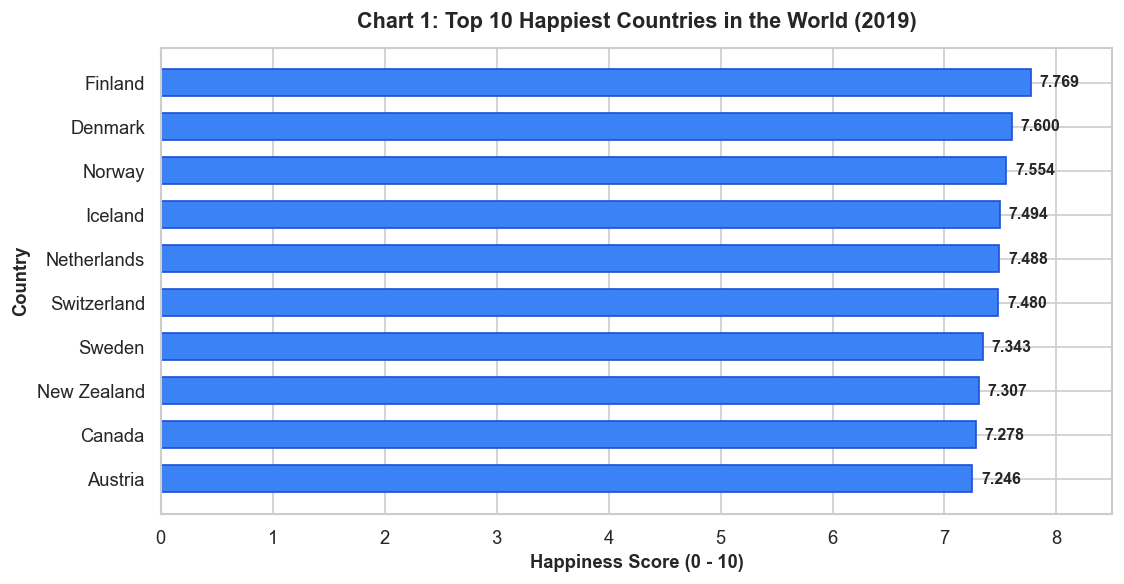

In [19]:
plt.figure(figsize=(9.5, 5))
top10_plot = df_2019.nsmallest(10, "rank").sort_values("score", ascending=True)
bars = plt.barh(top10_plot["country"], top10_plot["score"], color="#3b82f6", edgecolor="#1d4ed8", height=0.62)
plt.xlim(0, 8.5)
plt.title("Chart 1: Top 10 Happiest Countries in the World (2019)", pad=12)
plt.xlabel("Happiness Score (0 - 10)")
plt.ylabel("Country")

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.08, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va="center", ha="left", fontsize=9.5, fontweight="bold")
plt.show()


### 📈 Chart 2: Line Chart — 5-Year Regional Happiness Trends (2015–2019)

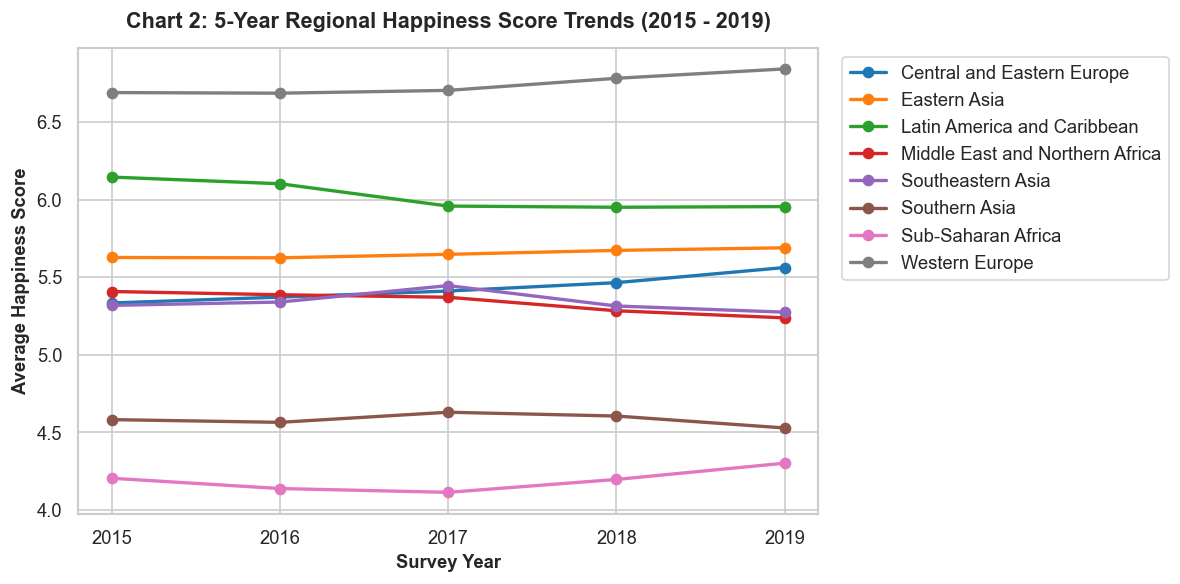

In [20]:
plt.figure(figsize=(10, 5))
reg_trends = all_years_df.groupby(["year", "region"])["score"].mean().unstack("region")
major_regions = [r for r in reg_trends.columns if r != "Other" and (df_2019["region"] == r).sum() >= 4]

palette = sns.color_palette("tab10", len(major_regions))
for i, reg in enumerate(major_regions):
    plt.plot(reg_trends.index, reg_trends[reg], marker="o", linewidth=2.0, label=reg, color=palette[i])

plt.xticks(range(2015, 2020))
plt.title("Chart 2: 5-Year Regional Happiness Score Trends (2015 - 2019)", pad=12)
plt.xlabel("Survey Year")
plt.ylabel("Average Happiness Score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.show()


### 📉 Chart 3: Histogram with KDE — Global Score Distribution (2019)

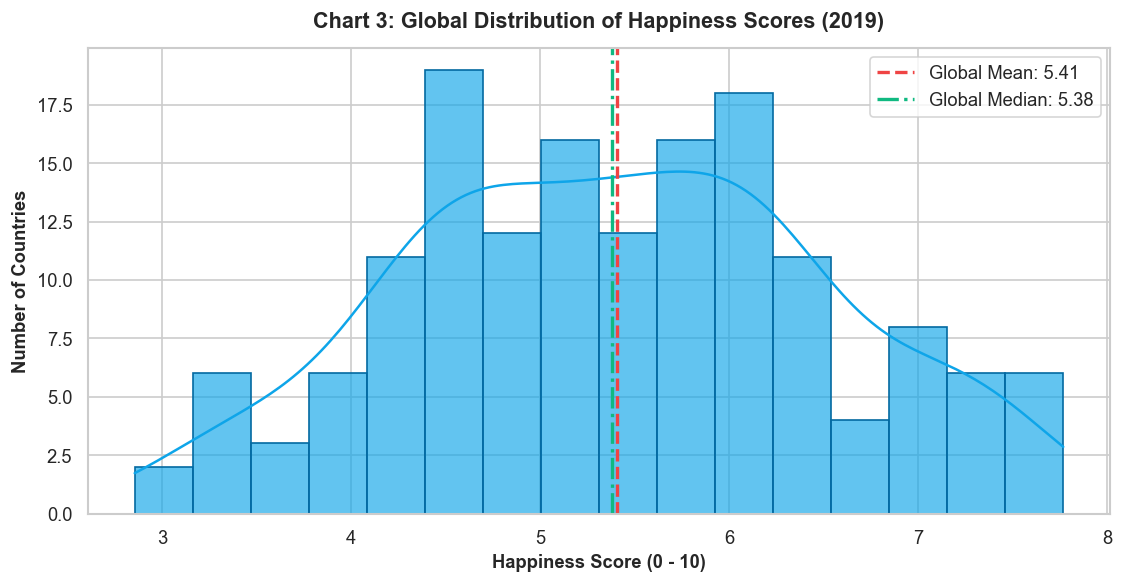

In [21]:
plt.figure(figsize=(9.5, 5))
sns.histplot(df_2019["score"], kde=True, bins=16, color="#0ea5e9", edgecolor="#0369a1", alpha=0.65)
mean_val = df_2019["score"].mean()
med_val = df_2019["score"].median()

plt.axvline(mean_val, color="#ef4444", linestyle="--", linewidth=2, label=f"Global Mean: {mean_val:.2f}")
plt.axvline(med_val, color="#10b981", linestyle="-.", linewidth=2, label=f"Global Median: {med_val:.2f}")

plt.title("Chart 3: Global Distribution of Happiness Scores (2019)", pad=12)
plt.xlabel("Happiness Score (0 - 10)")
plt.ylabel("Number of Countries")
plt.legend(frameon=True)
plt.show()


### 🔵 Chart 4: Scatter Plot — GDP per Capita vs. Happiness Score

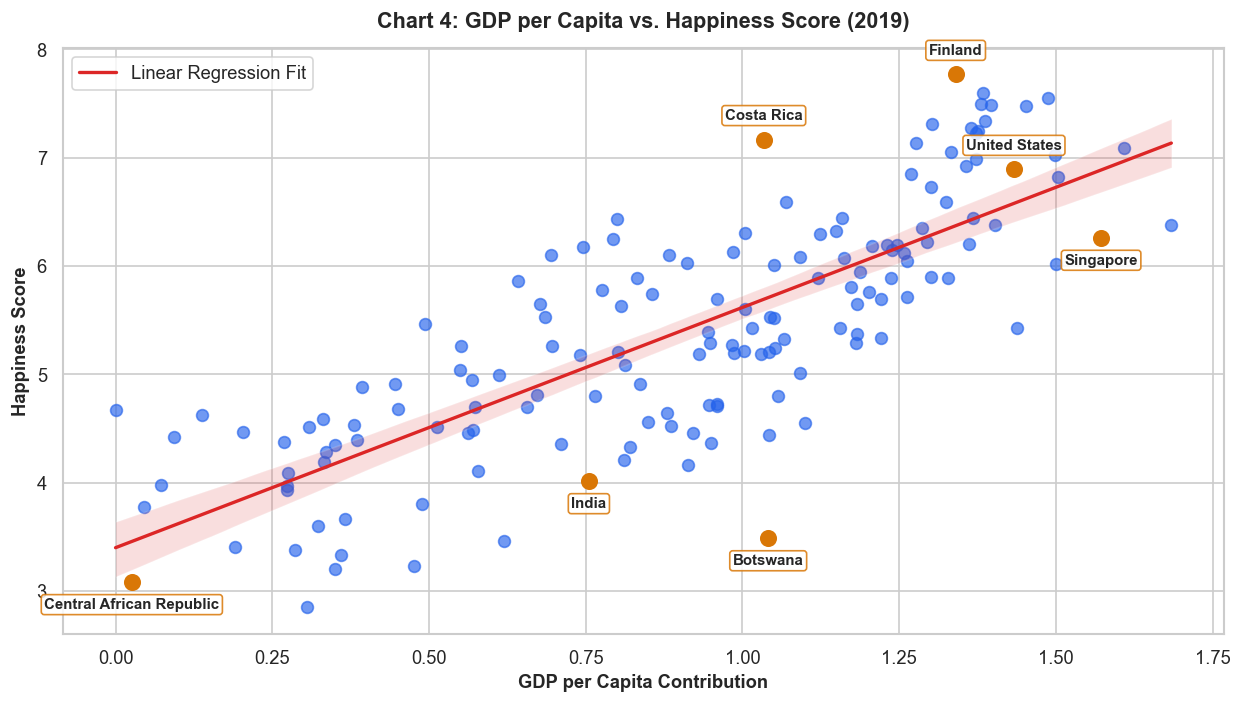

In [22]:
plt.figure(figsize=(10.5, 6))
sns.regplot(data=df_2019, x="gdp", y="score",
            scatter_kws={"alpha": 0.65, "color": "#2563eb", "s": 50},
            line_kws={"color": "#dc2626", "linewidth": 2, "label": "Linear Regression Fit"})

# Annotate notable countries
notable = ["Finland", "Costa Rica", "Singapore", "Botswana", "India", "United States", "Central African Republic"]
for country in notable:
    match = df_2019[df_2019["country"] == country]
    if not match.empty:
        x_val = match["gdp"].values[0]
        y_val = match["score"].values[0]
        plt.scatter(x_val, y_val, color="#d97706", s=85, zorder=5)
        offset = 12 if country in ["Costa Rica", "Finland", "United States"] else -16
        plt.annotate(country, (x_val, y_val), textcoords="offset points", xytext=(0, offset),
                     ha="center", fontsize=9, fontweight="bold",
                     bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#d97706", alpha=0.85))

plt.title("Chart 4: GDP per Capita vs. Happiness Score (2019)", pad=12)
plt.xlabel("GDP per Capita Contribution")
plt.ylabel("Happiness Score")
plt.legend(loc="upper left")
plt.show()


### 🍩 Chart 5: Donut Chart — Regional Representation in 2019 Sample

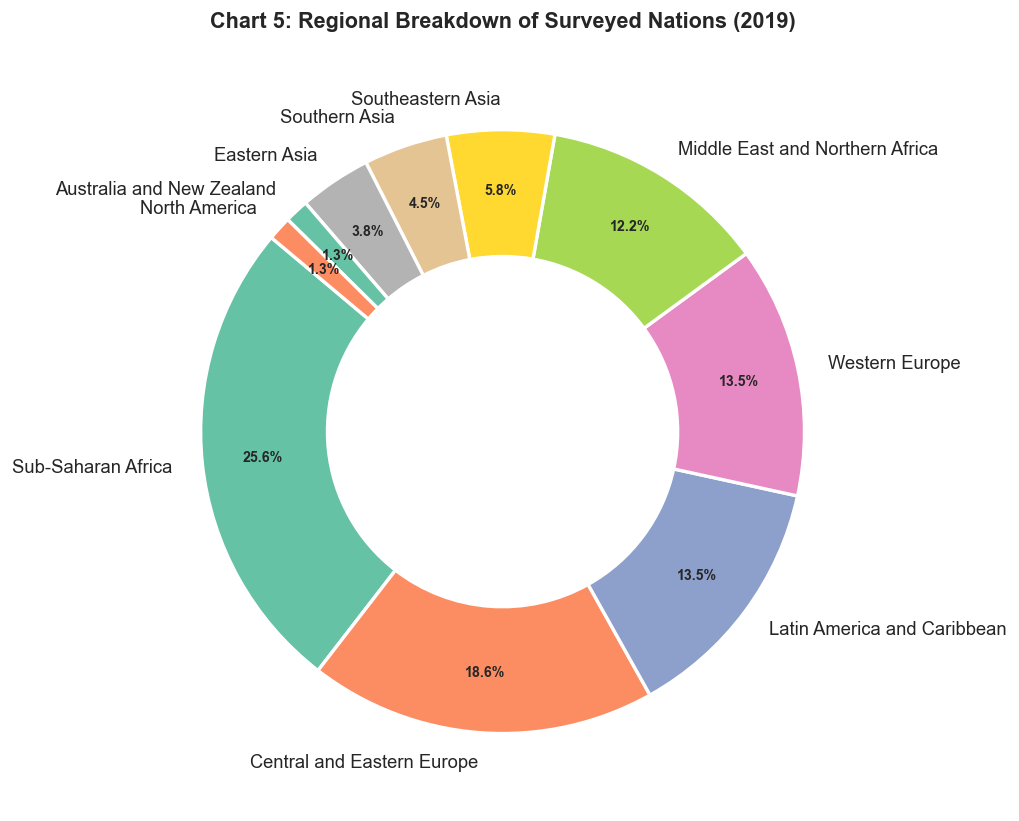

In [23]:
plt.figure(figsize=(8, 7))
reg_counts = df_2019["region"].value_counts()
colors = sns.color_palette("Set2", len(reg_counts))
wedges, texts, autotexts = plt.pie(
    reg_counts, labels=reg_counts.index, autopct="%1.1f%%",
    startangle=140, colors=colors, pctdistance=0.8,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2)
)
for at in autotexts:
    at.set_fontsize(8.5)
    at.set_weight("bold")

plt.title("Chart 5: Regional Breakdown of Surveyed Nations (2019)", pad=16)
plt.show()


### 🔥 Chart 6: Heatmap — Correlation Matrix of Happiness Dimensions

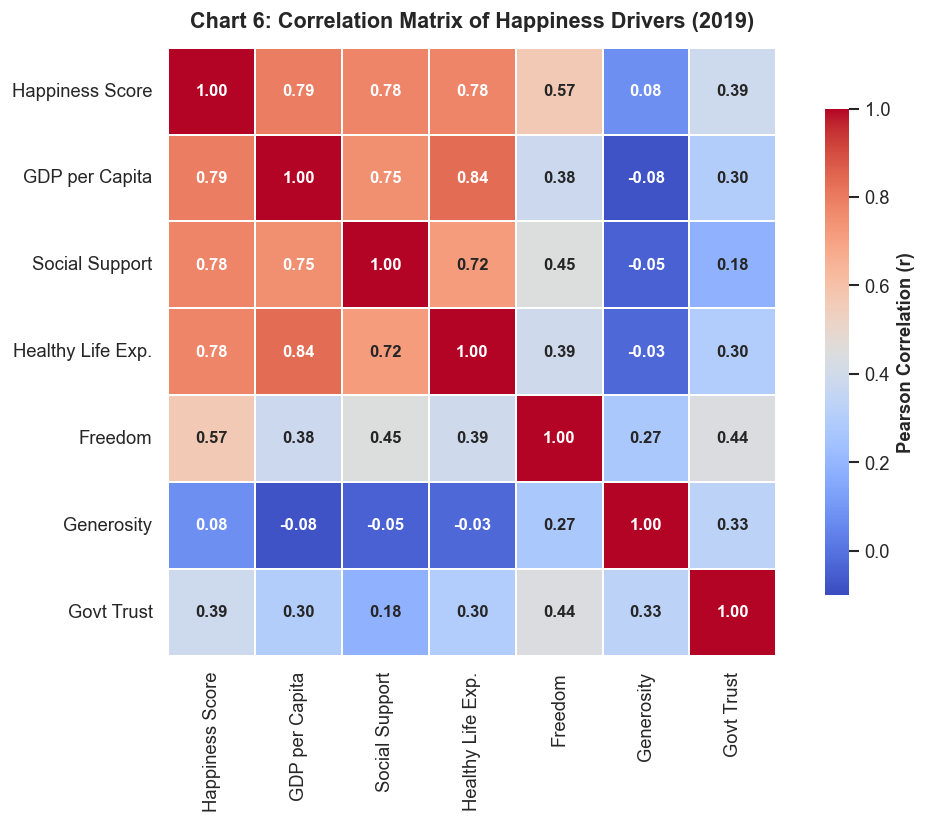

In [24]:
plt.figure(figsize=(9, 7))
corr_factors = ["score", "gdp", "social", "health", "freedom", "generosity", "corruption"]
corr_mat = df_2019[corr_factors].corr()
labels = {
    "score": "Happiness Score", "gdp": "GDP per Capita", "social": "Social Support",
    "health": "Healthy Life Exp.", "freedom": "Freedom", "generosity": "Generosity", "corruption": "Govt Trust"
}
sns.heatmap(corr_mat.rename(index=labels, columns=labels), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-0.1, vmax=1.0, square=True, linewidths=1.2,
            cbar_kws={"shrink": 0.8, "label": "Pearson Correlation (r)"},
            annot_kws={"size": 10, "weight": "bold"})
plt.title("Chart 6: Correlation Matrix of Happiness Drivers (2019)", pad=12)
plt.show()


### 📦 Bonus Chart 7: Box Plot — Happiness Disparity Across Regions

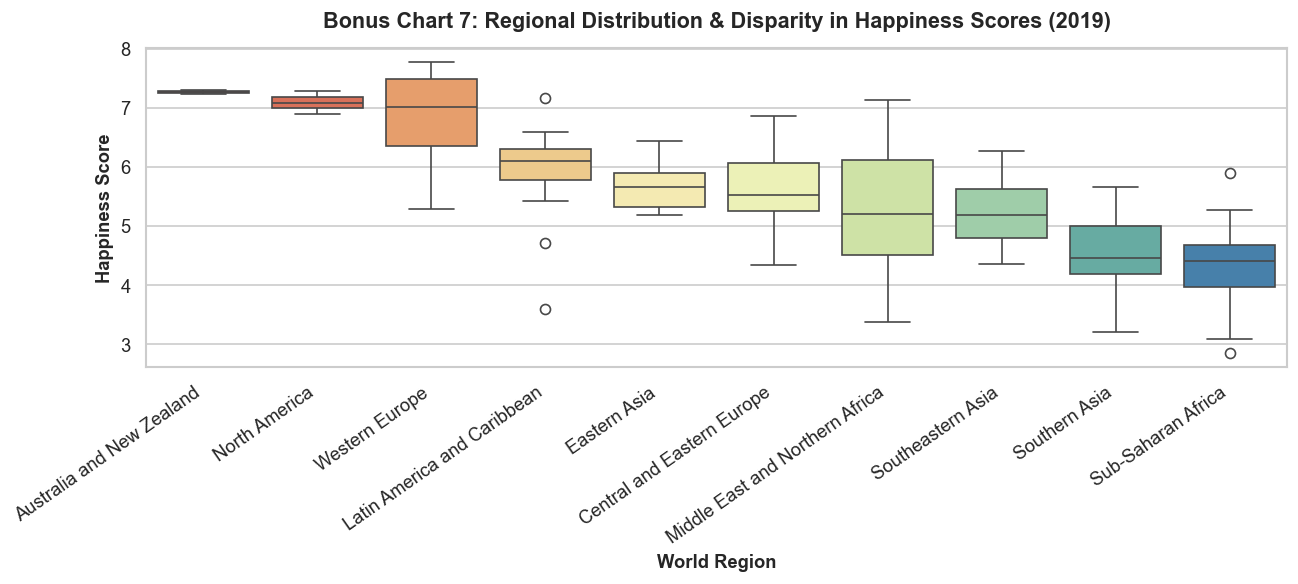

In [25]:
plt.figure(figsize=(11, 5))
order_reg = df_2019.groupby("region")["score"].median().sort_values(ascending=False).index
sns.boxplot(data=df_2019, x="region", y="score", order=order_reg, palette="Spectral")
plt.title("Bonus Chart 7: Regional Distribution & Disparity in Happiness Scores (2019)", pad=12)
plt.xlabel("World Region")
plt.ylabel("Happiness Score")
plt.xticks(rotation=35, ha="right")
plt.show()


---
## 📑 Step 5 — Insights Report & Recommendations

### 5 Data-Backed Business & Policy Insights:
1. **Economic Foundation is Essential but Insufficient (Chart 4 & 6)**:
   While GDP per capita exhibits the strongest positive correlation with happiness ($r = 0.794$), wealth alone does not guarantee high well-being. Nations like Singapore and Qatar have top-tier GDP per capita (~$1.68$) yet rank 34th and 29th in happiness. In contrast, Costa Rica achieves 12th place globally despite having roughly two-thirds the GDP per capita of wealthy peers ($1.03$ vs $1.68$), driven by robust social safety nets and healthcare access.
2. **Social Capital and Mutual Support Are Primary Multipliers (Chart 6 & Table Q1)**:
   Social support has the second-highest correlation ($r = 0.777$) with happiness. Between the top 10 happiest nations and the bottom 5, the social support score drops by nearly $3.5\times$ (from $1.53$ to $0.44$). Organizations and policymakers should invest aggressively in community resilience, psychological safety, and social welfare infrastructure.
3. **Geographic Inequality Is Extreme but Stable (Chart 2 & 5)**:
   Western Europe and North America consistently lead global happiness scores with regional averages above $6.80$, whereas Sub-Saharan Africa lags at $4.31$ (a $2.5$-point gap). Over the 5-year longitudinal analysis (2015–2019), regional trajectories remained remarkably stable, indicating that structural reforms require decades of sustained capital and institutional reinforcement.
4. **The Economic Efficiency Gap — Punching Above Wealth (Table Q5 & Chart 4)**:
   Latin American countries consistently rank much higher in happiness than their economic rank would predict (e.g., Costa Rica $+43$ spots, Mexico $+37$ spots, Guatemala $+47$ spots). Conversely, certain African countries such as Botswana (Rank 148 in happiness vs Rank 75 in GDP, gap of $-73$) suffer severely from inequality and institutional challenges despite mineral wealth.
5. **Generosity Does Not Drive National Happiness (Chart 6 & Table Q2)**:
   Generosity showed an almost negligible correlation with overall happiness ($r = 0.076$). This counter-intuitive finding demonstrates that while individual charitable acts provide personal fulfillment, broad national happiness is rooted primarily in systemic institutional health, economic security, and public healthcare rather than voluntary philanthropy.

---

### 😲 Finding That Surprised Me the Most (3–5 Lines):
> *"The most surprising discovery was the complete divergence between wealth and happiness in the **Rank Disparity Analysis (Question 5 & Chart 4)**. Nations like Botswana and Qatar produce extraordinarily high economic output per capita, yet score lower in life satisfaction than Latin American nations with a fraction of their wealth like Costa Rica and Guatemala. This conclusively disproves the premise that maximizing GDP alone optimizes human well-being, highlighting that social cohesion, freedom, and healthcare access are the true linchpins of life satisfaction."*
